# Baseline: import, histograms, segmentation

1. Import the image (config `input`) and save it to `.zarr`.
2. Per-pixel histograms of every channel.
3. Every segmentation listed under `segmentation` in the config (e.g. DAPI only, membrane only,
   membrane + DAPI), each with mean, sum and max intensity of every channel per object.

Segmentation uses the GPU (MPS on the Mac). Paths come from the config and `.env`.
The same steps run without the notebook with `python -m macroseg.baseline <config>`.

In [2]:
import shutil
from pathlib import Path

from spatialdata import read_zarr

from macroseg.baseline import expand, measure, segment
from macroseg.config import load_config
from macroseg.histograms import channel_summary, plot_histograms, sample_pixels
from macroseg.ingest import ingest

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = load_config(ROOT / "configs" / "exp201_test_crop.yaml")

OVERWRITE = False  # True rebuilds the .zarr from the raw image

zarr_path = Path(cfg.zarr)
element = cfg.image.element

/Users/massimoz/Documents/macroseg/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Import

In [3]:
if zarr_path.exists() and not OVERWRITE:
    print(f"Reusing {zarr_path}")
else:
    zarr_path.parent.mkdir(parents=True, exist_ok=True)
    if zarr_path.exists():
        shutil.rmtree(zarr_path)
    ingest(cfg.input, element).write(zarr_path)
sdata = read_zarr(zarr_path)
sdata

Reusing /Users/massimoz/Documents/macroseg/data/runs/exp201_test_crop.zarr


no parent found for <ome_zarr.reader.Label object at 0x11f1ff380>: None
no parent found for <ome_zarr.reader.Label object at 0x11f338550>: None
no parent found for <ome_zarr.reader.Label object at 0x11f338910>: None
no parent found for <ome_zarr.reader.Label object at 0x11f2f5ba0>: None
no parent found for <ome_zarr.reader.Label object at 0x11f2f6060>: None
no parent found for <ome_zarr.reader.Label object at 0x11f2cf530>: None


SpatialData object, with associated Zarr store: /Users/massimoz/Documents/macroseg/data/runs/exp201_test_crop.zarr
├── Images
│     └── 'macsima_image': DataArray[cyx] (6, 2048, 2048)
├── Labels
│     ├── 'exp201_test_crop_r01': DataArray[yx] (2048, 2048)
│     ├── 'membrane': DataArray[yx] (2048, 2048)
│     ├── 'membrane_dapi': DataArray[yx] (2048, 2048)
│     ├── 'membrane_dapi_f480': DataArray[yx] (2048, 2048)
│     ├── 'nuclei': DataArray[yx] (2048, 2048)
│     └── 'nuclei_expanded': DataArray[yx] (2048, 2048)
└── Tables
      ├── 'exp201_test_crop_r01_intensities': AnnData (1696, 6)
      ├── 'membrane_dapi_f480_intensities': AnnData (1835, 6)
      ├── 'membrane_dapi_intensities': AnnData (1587, 6)
      ├── 'membrane_intensities': AnnData (1441, 6)
      ├── 'nuclei_expanded_intensities': AnnData (1911, 6)
      └── 'nuclei_intensities': AnnData (1911, 6)
with coordinate systems:
    ▸ 'global', with elements:
        macsima_image (Images), exp201_test_crop_r01 (Labels), membr

## 2. Pixel histograms
Log axes; dashed lines at the 1st, 50th and 99th percentiles. Large images are subsampled on a regular grid.

,p1,p50,p99,p99.9
DAPI,1137.0,18407.0,47392.0,56124.850
NaK_ATPase,288.0,1185.0,2409.0,2918.000
F480,0.0,80.0,1002.0,2455.000
autofluo_FITC,3410.0,4354.0,6320.0,7786.425
autofluo_PE,0.0,0.0,93.0,176.425
autofluo_APC,272.0,421.0,883.0,1255.425


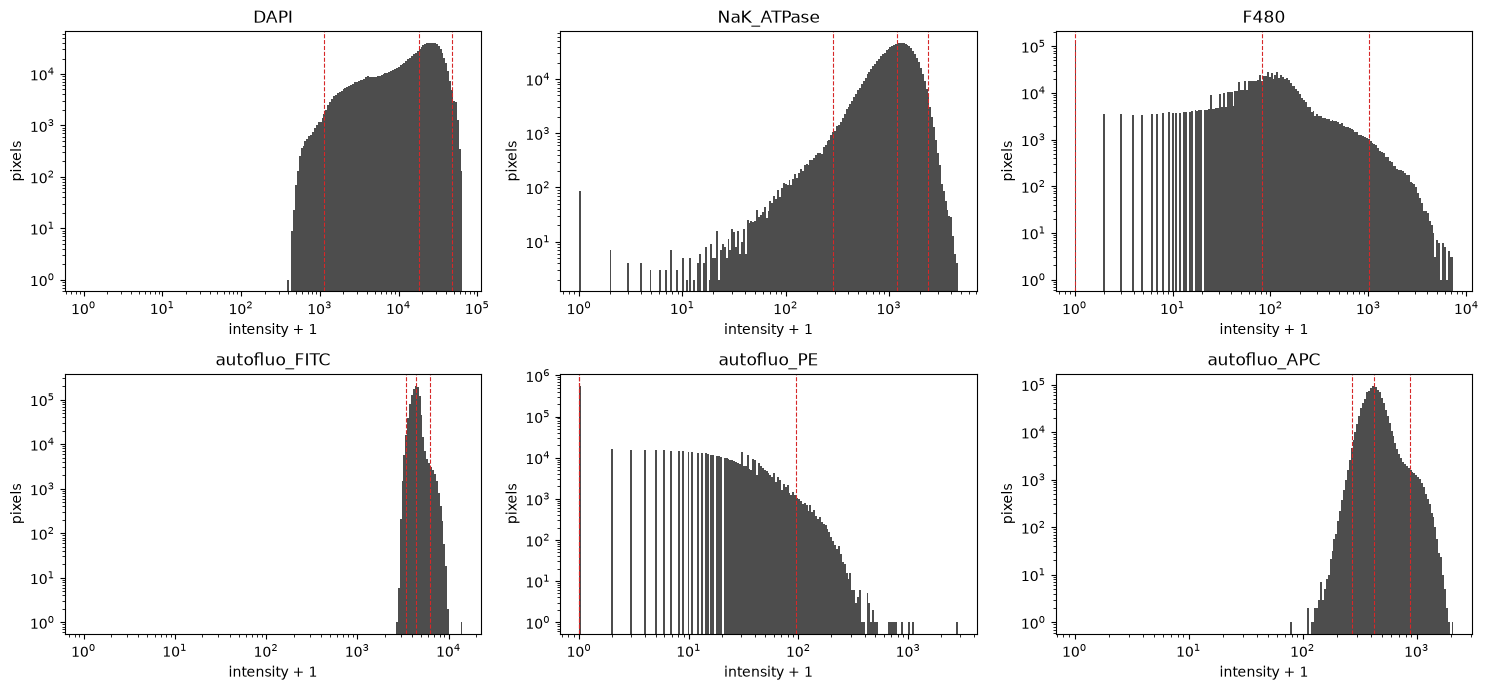

In [4]:
pixels = sample_pixels(sdata, element)
plot_histograms(pixels);
channel_summary(pixels)

## 3. Segmentations
One entry per segmentation under `segmentation` in the config: a Cellpose run on its channels, or (`expand`)
an earlier segmentation grown by `distance_um`. Each writes a labels element (same name) and a table `<name>_intensities`.

In [5]:
for step in cfg.segmentation:
    if step.expand is not None:
        print(f"{step.labels}: {step.expand} grown by {step.distance_um} µm")
        sdata = expand(sdata, step)
    else:
        print(f"{step.labels}: {list(step.channels)}")
        sdata = segment(sdata, element, step)
    sdata = measure(sdata, element, step.labels)

{step.labels: sdata.tables[f"{step.labels}_intensities"].n_obs for step in cfg.segmentation}

nuclei: ['DAPI']


/Users/massimoz/Documents/macroseg/.venv/lib/python3.13/site-packages/cellpose/dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:855.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),
2026-10-26 12:49:56.821 | INFO     | harpy.image.segmentation._segmentation:_segment:687 - Linking labels across chunks.
2026-10-26 12:49:56.824 | INFO     | harpy.image._manager:add_element:47 - Writing results to element 'nuclei'
2026-10-26 12:49:56.829 | INFO     | harpy._storage._spatialdata:_replace_element_on_disk:186 - Writing replacement labels/nuclei to staging at '/Users/m

nuclei_expanded: nuclei grown by 3.0 µm


2026-10-26 12:49:58.790 | INFO     | harpy.image.segmentation._map:_combine_dask_arrays:339 - Linking labels across chunks.
2026-10-26 12:49:58.796 | INFO     | harpy.image._manager:add_element:47 - Writing results to element 'nuclei_expanded'
2026-10-26 12:49:58.800 | INFO     | harpy._storage._spatialdata:_replace_element_on_disk:186 - Writing replacement labels/nuclei_expanded to staging at '/Users/massimoz/Documents/macroseg/data/runs/.exp201_test_crop.zarr.harpy-replace-kn7r2o81/store.zarr'.
2026-10-26 12:49:58.887 | INFO     | harpy._storage._spatialdata:_replace_element_on_disk:188 - Finished writing staged replacement labels/nuclei_expanded.
2026-10-26 12:49:58.888 | INFO     | harpy._storage._publication:_publish_staged_paths:119 - Publishing 1 path update(s) for 'replace' to ['/Users/massimoz/Documents/macroseg/data/runs/exp201_test_crop.zarr/labels/nuclei_expanded'].
2026-10-26 12:49:58.888 | INFO     | harpy._storage._publication:_publish_staged_paths:130 - Removing staging

membrane: ['NaK_ATPase']


...

membrane_dapi: ['NaK_ATPase', 'DAPI']


2026-10-26 12:51:16.282 | INFO     | harpy.image.segmentation._segmentation:_segment:687 - Linking labels across chunks.
2026-10-26 12:51:16.286 | INFO     | harpy.image._manager:add_element:47 - Writing results to element 'membrane_dapi'
2026-10-26 12:51:16.290 | INFO     | harpy._storage._spatialdata:_replace_element_on_disk:186 - Writing replacement labels/membrane_dapi to staging at '/Users/massimoz/Documents/macroseg/data/runs/.exp201_test_crop.zarr.harpy-replace-7nm6is8n/store.zarr'.
2026-10-26 12:51:16.372 | INFO     | harpy._storage._spatialdata:_replace_element_on_disk:188 - Finished writing staged replacement labels/membrane_dapi.
2026-10-26 12:51:16.373 | INFO     | harpy._storage._publication:_publish_staged_paths:119 - Publishing 1 path update(s) for 'replace' to ['/Users/massimoz/Documents/macroseg/data/runs/exp201_test_crop.zarr/labels/membrane_dapi'].
2026-10-26 12:51:16.373 | INFO     | harpy._storage._publication:_publish_staged_paths:130 - Removing staging workspace 

membrane_dapi_f480: ['NaK_ATPase', 'DAPI', 'F480']


2026-10-26 12:51:54.422 | INFO     | harpy.image.segmentation._segmentation:_segment:687 - Linking labels across chunks.
2026-10-26 12:51:54.425 | INFO     | harpy.image._manager:add_element:47 - Writing results to element 'membrane_dapi_f480'
2026-10-26 12:51:54.429 | INFO     | harpy._storage._spatialdata:_replace_element_on_disk:186 - Writing replacement labels/membrane_dapi_f480 to staging at '/Users/massimoz/Documents/macroseg/data/runs/.exp201_test_crop.zarr.harpy-replace-mva093bx/store.zarr'.
2026-10-26 12:51:54.517 | INFO     | harpy._storage._spatialdata:_replace_element_on_disk:188 - Finished writing staged replacement labels/membrane_dapi_f480.
2026-10-26 12:51:54.518 | INFO     | harpy._storage._publication:_publish_staged_paths:119 - Publishing 1 path update(s) for 'replace' to ['/Users/massimoz/Documents/macroseg/data/runs/exp201_test_crop.zarr/labels/membrane_dapi_f480'].
2026-10-26 12:51:54.519 | INFO     | harpy._storage._publication:_publish_staged_paths:130 - Removin

{'nuclei': 1911,
 'nuclei_expanded': 1911,
 'membrane': 1441,
 'membrane_dapi': 1587,
 'membrane_dapi_f480': 1835}